<a href="https://colab.research.google.com/github/rpasquini/herramientas-econometricas/blob/main/Ejemplos_Regresion_Multiple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regresión múltiple, variables categóricas e interacciones

Este notebook acompaña las slides del Día 3. Ejemplo principal: **ingresos, escolaridad y sexo en CABA (EAH 2016)**. Segundo ejemplo: **resultados escolares** (308 escuelas), que usamos para sesgo por variable omitida y multicolinealidad.

Plan:
1. Datos
2. Regresión múltiple: interpretación
3. Frisch-Waugh-Lovell: qué significa "controlar por"
4. Varianza y multicolinealidad
5. Sesgo por variable omitida
6. Variables categóricas
7. Interacciones
8. Práctica

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col
from statsmodels.stats.outliers_influence import variance_inflation_factor

## 1. Datos

In [2]:
base = 'https://raw.githubusercontent.com/rpasquini/herramientas-econometricas/main/datos/'

df = pd.read_csv(base + 'eah2016_individual.csv')
df = df[(df['ingtot_2'] > 0) & (df['aesc'] != 0) & (df['aesc'] != 99)].copy()
df['logingreso'] = np.log(df['ingtot_2'])
df['mujer'] = (df['sexo'] == 'mujer').astype(int)   # dummy: 1 = mujer, 0 = varón
df[['logingreso', 'aesc', 'mujer', 'edad', 'estado']].describe(include='all')

,logingreso,aesc,mujer,edad,estado
count,10048.000000,10048.000000,10048.000000,10048.000000,10048
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,ocupado
freq,NaN,NaN,NaN,NaN,7258
mean,9.286783,12.623507,0.526572,48.147193,NaN
std,0.858955,3.735864,0.499318,18.979816,NaN
min,3.178054,1.000000,0.000000,10.000000,NaN
25%,8.699515,10.000000,0.000000,32.000000,NaN
50%,9.392662,12.000000,1.000000,46.000000,NaN
75%,9.876206,15.000000,1.000000,63.000000,NaN


Escuelas (cada fila es una escuela; `iecep` es un indicador de resultados y `nivel_educ_madre` el nivel educativo promedio de las madres):

In [3]:
edu = pd.read_csv(base + 'estadistica-educativa.csv')
edu['privada'] = (edu['tipo_gestion'] == 'Privada').astype(int)
edu[['iecep', 'privada', 'nivel_educ_madre', 'tasa_repeticion_2012']].describe()

,iecep,privada,nivel_educ_madre,tasa_repeticion_2012
count,308.000000,308.000000,308.000000,308.000000
mean,5.988627,0.623377,5.417110,9.221925
std,1.320348,0.485328,0.898175,10.129256
min,1.394420,0.000000,2.840000,0.000000
25%,5.185740,0.000000,4.825000,1.547407
50%,6.282550,1.000000,5.565000,5.205110
75%,7.061680,1.000000,6.142500,13.927175
max,7.960080,1.000000,6.810000,51.679600


## 2. Regresión múltiple: interpretación

Empezamos con el modelo simple de la clase anterior, y le agregamos el sexo:

In [4]:
m1 = smf.ols('logingreso ~ aesc', data=df).fit()
m2 = smf.ols('logingreso ~ aesc + mujer', data=df).fit()
print(m2.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      8.1619      0.028    293.341      0.000       8.107       8.216
aesc           0.1015      0.002     50.280      0.000       0.098       0.105
mujer         -0.2962      0.015    -19.620      0.000      -0.326      -0.267


**Interpretación**
- $\hat\beta_{aesc}$: comparando personas **del mismo sexo**, un año más de escolaridad se asocia con un ingreso $\approx 10.7\%$ mayor.
- $\hat\beta_{mujer}$: comparando personas **con la misma escolaridad**, las mujeres ganan en promedio $e^{\hat\beta_{mujer}}-1$ (en %) respecto de los varones.

In [5]:
print(f"Efecto de un año de escolaridad: {100*(np.exp(m2.params['aesc'])-1):.1f}%")
print(f"Diferencia mujeres vs varones   : {100*(np.exp(m2.params['mujer'])-1):.1f}%")

Efecto de un año de escolaridad: 10.7%
Diferencia mujeres vs varones   : -25.6%


Comparamos el modelo simple con el múltiple:

In [6]:
summary_col([m1, m2], stars=True, float_format='%.4f',
            model_names=['simple', 'múltiple'], info_dict={'N': lambda x: f'{int(x.nobs)}'})

,simple,múltiple
Intercept,7.9995***,8.1619***
,(0.0271),(0.0278)
aesc,0.1020***,0.1015***
,(0.0021),(0.0020)
mujer,,-0.2962***
,,(0.0151)
R-squared,0.1967,0.2264
R-squared Adj.,0.1966,0.2262
N,10048,10048


El coeficiente de escolaridad casi no cambió. Esto ocurre porque, en la muestra, varones y mujeres tienen casi la misma escolaridad (lo veremos en la Sección 5). Sí mejoró el $R^2$ y bajó algo el error estándar.

In [7]:
print(df.groupby('mujer')[['aesc', 'logingreso']].mean())

            aesc  logingreso
mujer                       
0      12.674585    9.447948
1      12.577585    9.141884


### Dos rectas paralelas

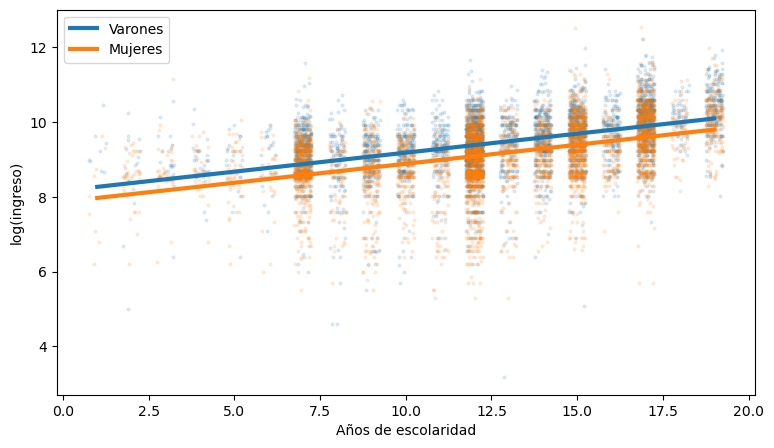

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
rng = np.random.default_rng(0)
jit = rng.uniform(-.25, .25, len(df))
xs = np.linspace(df['aesc'].min(), df['aesc'].max(), 50)
for m, c, lab in ((0, 'tab:blue', 'Varones'), (1, 'tab:orange', 'Mujeres')):
    s = df['mujer'] == m
    ax.scatter(df.loc[s, 'aesc'] + jit[s.values], df.loc[s, 'logingreso'], s=4, alpha=.12, color=c)
    ax.plot(xs, m2.params['Intercept'] + m2.params['aesc'] * xs + m2.params['mujer'] * m, color=c, lw=3, label=lab)
ax.set_xlabel('Años de escolaridad'); ax.set_ylabel('log(ingreso)'); ax.legend()

### Agregando la edad (cuadrática)

In [9]:
m3 = smf.ols('logingreso ~ aesc + mujer + edad + I(edad**2)', data=df).fit()
print(m3.summary().tables[1])
print('R2:', round(m3.rsquared, 3))
print('Edad que maximiza el ingreso:', -m3.params['edad'] / (2 * m3.params['I(edad ** 2)']))

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        6.9242      0.054    127.685      0.000       6.818       7.031
aesc             0.1011      0.002     50.482      0.000       0.097       0.105
mujer           -0.3098      0.015    -21.157      0.000      -0.338      -0.281
edad             0.0480      0.002     22.516      0.000       0.044       0.052
I(edad ** 2)    -0.0004   2.06e-05    -19.213      0.000      -0.000      -0.000
R2: 0.281
Edad que maximiza el ingreso: 60.58899376471782


## 3. Frisch-Waugh-Lovell: qué significa "controlar por"

El coeficiente de $x_j$ en la regresión múltiple es la pendiente de $y$ sobre la parte de $x_j$ **no explicada** por los demás regresores. Lo verificamos para `aesc` en el modelo con `mujer`, `edad` y `edad²`:

In [10]:
# Paso 1: residuo de regresar aesc sobre los demás regresores
aux = smf.ols('aesc ~ mujer + edad + I(edad**2)', data=df).fit()
df['aesc_limpia'] = aux.resid

# Paso 2: regresar y sobre ese residuo
fwl = smf.ols('logingreso ~ aesc_limpia', data=df).fit()

print('Coeficiente en la regresión múltiple:', m3.params['aesc'])
print('Coeficiente por FWL                 :', fwl.params['aesc_limpia'])

Coeficiente en la regresión múltiple: 0.10110339908010202
Coeficiente por FWL                 : 0.10110339908010355


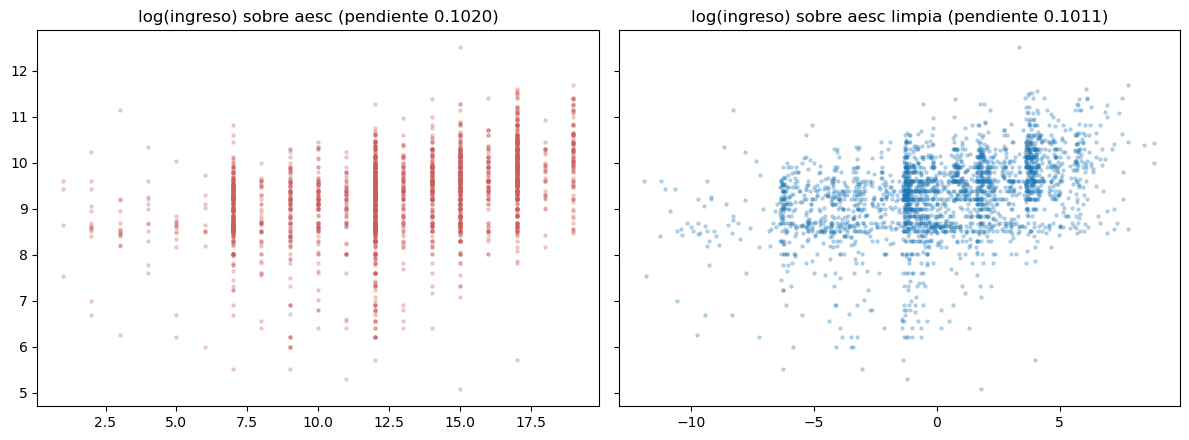

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
s = df.sample(2500, random_state=1)
axs[0].scatter(s['aesc'], s['logingreso'], s=5, alpha=.25, color='indianred')
axs[0].set_title(f"log(ingreso) sobre aesc (pendiente {m1.params['aesc']:.4f})")
axs[1].scatter(s['aesc_limpia'], s['logingreso'], s=5, alpha=.25, color='tab:blue')
axs[1].set_title(f"log(ingreso) sobre aesc limpia (pendiente {fwl.params['aesc_limpia']:.4f})")
plt.tight_layout()

## 4. Varianza y multicolinealidad

$$Var(\hat\beta_j)=\frac{\sigma^2}{SST_j\,(1-R_j^2)}$$

donde $R_j^2$ es el $R^2$ de regresar $x_j$ sobre los demás regresores. Verificamos la fórmula para `aesc` en el modelo `m3`:

In [12]:
sigma2 = m3.mse_resid
SST_j = ((df['aesc'] - df['aesc'].mean())**2).sum()
R2_j = aux.rsquared          # R2 de la regresión auxiliar de aesc sobre los demás

se_formula = np.sqrt(sigma2 / (SST_j * (1 - R2_j)))
print('SE por la fórmula:', se_formula)
print('SE de statsmodels:', m3.bse['aesc'])
print('VIF de aesc      :', 1 / (1 - R2_j))

SE por la fórmula: 0.0020027511333777525
SE de statsmodels: 0.0020027511333777373
VIF de aesc      : 1.0596968944738354


### Multicolinealidad imperfecta: resultados escolares

Variable explicada: tasa de repetición 2012. Regresores: % de alumnos con nivel alto en Matemática, Ciencias Naturales y Ciencias Sociales (miden cosas parecidas).

In [13]:
print(edu[['one_alto_mat', 'one_alto_cs_nat', 'one_alto_cs_soc']].corr().round(2))

                 one_alto_mat  one_alto_cs_nat  one_alto_cs_soc
one_alto_mat             1.00             0.74             0.68
one_alto_cs_nat          0.74             1.00             0.71
one_alto_cs_soc          0.68             0.71             1.00


In [14]:
c1 = smf.ols('tasa_repeticion_2012 ~ one_alto_mat', data=edu).fit()
c3 = smf.ols('tasa_repeticion_2012 ~ one_alto_mat + one_alto_cs_nat + one_alto_cs_soc', data=edu).fit()

summary_col([c1, c3], stars=True, float_format='%.2f', model_names=['sólo Mat', 'las tres'])

,sólo Mat,las tres
Intercept,15.22***,17.58***
,(0.90),(1.04)
one_alto_mat,-23.54***,-9.47**
,(2.88),(4.37)
one_alto_cs_nat,,-10.03*
,,(5.88)
one_alto_cs_soc,,-13.56***
,,(4.70)
R-squared,0.18,0.23
R-squared Adj.,0.18,0.22


In [15]:
# Test t individuales vs. test F conjunto
print(c3.summary().tables[1])
print(f'Test F conjunto: F = {c3.fvalue:.1f}, p = {c3.f_pvalue:.2g}')

# VIF
X = c3.model.exog
for i, nombre in enumerate(c3.model.exog_names):
    if nombre != 'Intercept':
        print(f'VIF {nombre}: {variance_inflation_factor(X, i):.2f}')

                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          17.5814      1.044     16.839      0.000      15.527      19.636
one_alto_mat       -9.4725      4.373     -2.166      0.031     -18.078      -0.867
one_alto_cs_nat   -10.0345      5.878     -1.707      0.089     -21.601       1.531
one_alto_cs_soc   -13.5609      4.698     -2.886      0.004     -22.806      -4.316
Test F conjunto: F = 29.9, p = 5.8e-17
VIF one_alto_mat: 2.44
VIF one_alto_cs_nat: 2.69
VIF one_alto_cs_soc: 2.28


El efecto de Matemática pasa de un $t$ muy grande a uno chico, y su error estándar se multiplica por 1,5: el coeficiente se reparte entre variables que miden lo mismo. Pero el test $F$ conjunto rechaza con holgura: las tres son conjuntamente relevantes. La multicolinealidad afecta la **precisión**, no el sesgo.

### Multicolinealidad perfecta
Si incluimos años y meses de experiencia (o edad en años y en meses), un regresor es combinación lineal exacta del otro:

In [16]:
df['edad_meses'] = 12 * df['edad']
X = df[['edad', 'edad_meses']].assign(const=1.0).values
print('Columnas:', X.shape[1], '| Rango de la matriz de regresores:', np.linalg.matrix_rank(X))

Columnas: 3 | Rango de la matriz de regresores: 2


El rango es menor que el número de columnas: $X'X$ no es invertible y los coeficientes individuales no están identificados. (`statsmodels` no falla: usa una pseudo-inversa, y avisa en el summary sobre la matriz casi singular.)

In [17]:
perfecta = smf.ols('logingreso ~ aesc + edad + edad_meses', data=df).fit()
print(perfecta.summary().tables[1])
print(perfecta.summary().extra_txt)

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      7.5944      0.036    212.791      0.000       7.524       7.664
aesc           0.1077      0.002     52.428      0.000       0.104       0.112
edad        4.766e-05   2.79e-06     17.090      0.000    4.22e-05    5.31e-05
edad_meses     0.0006   3.35e-05     17.090      0.000       0.001       0.001
Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 1.55e-24. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.


## 5. Sesgo por variable omitida

Si el modelo verdadero es $y=\beta_0+\beta_1x_1+\beta_2x_2+\varepsilon$ y omitimos $x_2$:
$$\tilde\beta_1=\hat\beta_1+\hat\beta_2\,\hat\delta_1$$
donde $\hat\delta_1$ es la pendiente de $x_2$ sobre $x_1$. La identidad vale **exactamente** en la muestra.

### Ejemplo: ¿importa si la escuela es privada?

In [18]:
corto = smf.ols('iecep ~ privada', data=edu).fit()
largo = smf.ols('iecep ~ privada + nivel_educ_madre', data=edu).fit()
aux_e = smf.ols('nivel_educ_madre ~ privada', data=edu).fit()

summary_col([corto, largo], stars=True, float_format='%.3f', model_names=['corto', 'largo'])

,corto,largo
Intercept,5.225***,0.695*
,(0.110),(0.385)
privada,1.225***,0.090
,(0.139),(0.148)
nivel_educ_madre,,0.967***
,,(0.080)
R-squared,0.203,0.461
R-squared Adj.,0.200,0.458


In [19]:
b_corto = corto.params['privada']
b1_largo = largo.params['privada']
b2_largo = largo.params['nivel_educ_madre']
delta = aux_e.params['privada']

print(f'Coeficiente corto             : {b_corto:.4f}')
print(f'Coeficiente largo             : {b1_largo:.4f}')
print(f'beta2 (educación madre) x delta: {b2_largo:.4f} x {delta:.4f} = {b2_largo*delta:.4f}')
print(f'largo + beta2*delta           : {b1_largo + b2_largo*delta:.4f}')

Coeficiente corto             : 1.2248
Coeficiente largo             : 0.0898
beta2 (educación madre) x delta: 0.9668 x 1.1740 = 1.1350
largo + beta2*delta           : 1.2248


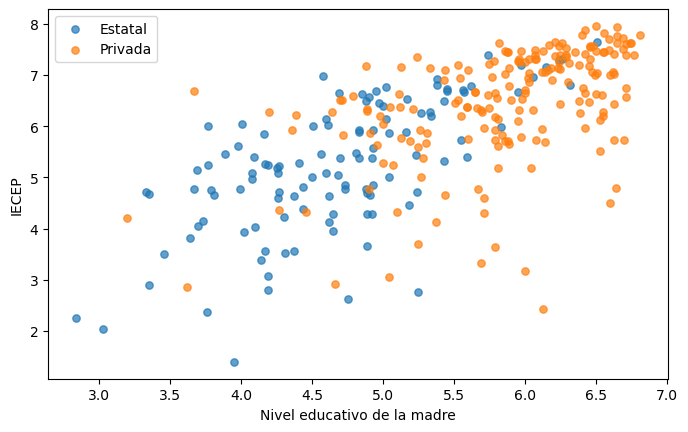

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for p, c, lab in ((0, 'tab:blue', 'Estatal'), (1, 'tab:orange', 'Privada')):
    s = edu['privada'] == p
    ax.scatter(edu.loc[s, 'nivel_educ_madre'], edu.loc[s, 'iecep'], s=28, alpha=.7, color=c, label=lab)
ax.set_xlabel('Nivel educativo de la madre'); ax.set_ylabel('IECEP'); ax.legend()

Las escuelas privadas tienen madres con más educación ($\hat\delta_1>0$) y esa educación se asocia con mejores resultados ($\hat\beta_2>0$): la regresión corta atribuye a la gestión privada lo que en buena parte es contexto socioeconómico. Este tema se retoma en la parte de inferencia causal.

### De vuelta a los ingresos: omitir el sexo
¿Hubiera sesgado el coeficiente de escolaridad omitir `mujer`? Depende de $\hat\delta$, la pendiente de `mujer` sobre `aesc`:

In [21]:
aux_s = smf.ols('mujer ~ aesc', data=df).fit()
print('delta (mujer ~ aesc):', aux_s.params['aesc'], ' t =', aux_s.tvalues['aesc'])
print('sesgo = beta_mujer x delta =', m2.params['mujer'] * aux_s.params['aesc'])
print('coef corto - coef largo    =', m1.params['aesc'] - m2.params['aesc'])

delta (mujer ~ aesc): -0.0017327890946231567  t = -1.299548093446011
sesgo = beta_mujer x delta = 0.0005132897248592652
coef corto - coef largo    = 0.0005132897248590201


Prácticamente no hay sesgo, porque la escolaridad casi no varía por sexo. Aun así incluir `mujer` mejora el ajuste y la precisión.

### Controles que son mediadores
Agregar `estado` (ocupado / desocupado / inactivo) reduce el coeficiente de escolaridad: parte del retorno de la educación opera *a través* de conseguir empleo. No siempre "más controles" es mejor.

In [22]:
m_estado = smf.ols('logingreso ~ aesc + mujer + C(estado)', data=df).fit()
print('aesc sin estado:', round(m2.params['aesc'], 4), ' | aesc con estado:', round(m_estado.params['aesc'], 4))

aesc sin estado: 0.1015  | aesc con estado: 0.0876


## 6. Variables categóricas

### Dos categorías: la dummy `mujer`
La dummy ya la construimos arriba. En `smf.ols` también se puede usar `C()` directamente sobre la variable original y `statsmodels` crea las dummies:

In [23]:
m_c = smf.ols('logingreso ~ aesc + C(sexo)', data=df).fit()
print(m_c.summary().tables[1])

                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            7.8657      0.027    286.816      0.000       7.812       7.919
C(sexo)[T.varon]     0.2962      0.015     19.620      0.000       0.267       0.326
aesc                 0.1015      0.002     50.280      0.000       0.098       0.105


Observen que `C(sexo)[T.varon]` es el opuesto de `mujer`: la categoría de referencia es la primera en orden alfabético (`mujer`). Mismas predicciones, otra codificación.

### $k$ categorías: estado ocupacional
`C(estado)` crea $k-1$ dummies. La categoría de referencia es la primera alfabéticamente (`desocupado`):

In [24]:
print(df['estado'].value_counts())
m_k = smf.ols('logingreso ~ aesc + mujer + C(estado)', data=df).fit()
print(m_k.summary().tables[1])

estado
ocupado       7258
inactivo      2470
desocupado     320
Name: count, dtype: int64
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 7.2620      0.046    156.325      0.000       7.171       7.353
C(estado)[T.inactivo]     0.7807      0.043     18.357      0.000       0.697       0.864
C(estado)[T.ocupado]      1.1697      0.041     28.462      0.000       1.089       1.250
aesc                      0.0876      0.002     44.379      0.000       0.084       0.091
mujer                    -0.2240      0.015    -15.364      0.000      -0.253      -0.195


Para cambiar la categoría de referencia:

In [25]:
m_k2 = smf.ols("logingreso ~ aesc + mujer + C(estado, Treatment(reference='ocupado'))", data=df).fit()
print(m_k2.summary().tables[1])
print('R2 con una referencia:', round(m_k.rsquared, 4), '| con otra:', round(m_k2.rsquared, 4))

                                                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   8.4317      0.028    301.319      0.000       8.377       8.487
C(estado, Treatment(reference='ocupado'))[T.desocupado]    -1.1697      0.041    -28.462      0.000      -1.250      -1.089
C(estado, Treatment(reference='ocupado'))[T.inactivo]      -0.3889      0.018    -22.220      0.000      -0.423      -0.355
aesc                                                        0.0876      0.002     44.379      0.000       0.084       0.091
mujer                                                      -0.2240      0.015    -15.364      0.000      -0.253      -0.195
R2 con una referencia: 0.3064 | con otra: 0.3064


Cambian los coeficientes (cada uno compara contra la referencia) pero no el ajuste ni las predicciones.

### La trampa de las variables dummy
Si incluimos las $k$ dummies **y** la constante, la suma de las dummies es igual a la constante: multicolinealidad perfecta.

In [26]:
dummies = pd.get_dummies(df['estado']).astype(float)
X = dummies.assign(const=1.0).values
print('Columnas:', X.shape[1], '| Rango:', np.linalg.matrix_rank(X))
print('¿Suma de las dummies == 1?', (dummies.sum(axis=1) == 1).all())

Columnas: 4 | Rango: 3
¿Suma de las dummies == 1? True


## 7. Interacciones

¿El retorno de la escolaridad difiere entre varones y mujeres? Agregamos el producto `aesc × mujer`. En `smf.ols`, `aesc * mujer` equivale a `aesc + mujer + aesc:mujer`.

In [27]:
m_int = smf.ols('logingreso ~ aesc * mujer', data=df).fit()
print(m_int.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      8.1636      0.040    205.604      0.000       8.086       8.241
aesc           0.1013      0.003     33.652      0.000       0.095       0.107
mujer         -0.2993      0.053     -5.602      0.000      -0.404      -0.195
aesc:mujer     0.0002      0.004      0.060      0.952      -0.008       0.008


- Pendiente de varones: $\hat\beta_1$ (`aesc`).
- Pendiente de mujeres: $\hat\beta_1+\hat\beta_3$ (`aesc` + `aesc:mujer`).
- El test $t$ de `aesc:mujer` evalúa $H_0:\beta_3=0$ (pendientes iguales).

In [28]:
b = m_int.params
print(f"Pendiente varones: {b['aesc']:.4f}")
print(f"Pendiente mujeres: {b['aesc'] + b['aesc:mujer']:.4f}")
print(f"Test de pendientes iguales: t = {m_int.tvalues['aesc:mujer']:.2f}, p = {m_int.pvalues['aesc:mujer']:.2f}")

Pendiente varones: 0.1013
Pendiente mujeres: 0.1016
Test de pendientes iguales: t = 0.06, p = 0.95


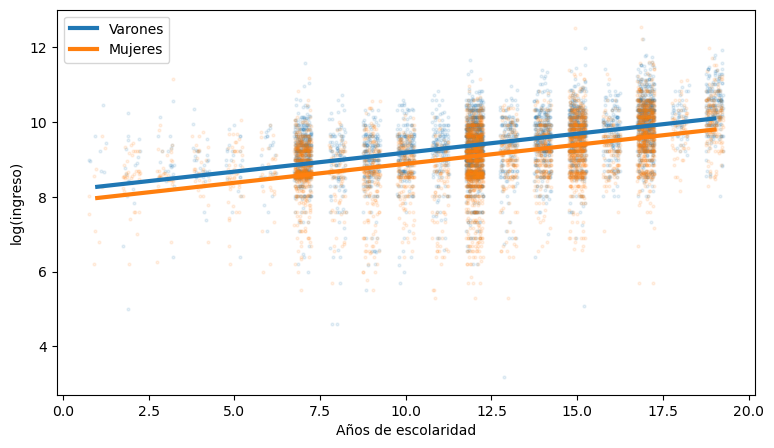

In [29]:
fig, ax = plt.subplots(figsize=(9, 5))
for m, c, lab in ((0, 'tab:blue', 'Varones'), (1, 'tab:orange', 'Mujeres')):
    s = df['mujer'] == m
    ax.scatter(df.loc[s, 'aesc'] + jit[s.values], df.loc[s, 'logingreso'], s=4, alpha=.10, color=c)
    ax.plot(xs, b['Intercept'] + b['aesc'] * xs + m * (b['mujer'] + b['aesc:mujer'] * xs), color=c, lw=3, label=lab)
ax.set_xlabel('Años de escolaridad'); ax.set_ylabel('log(ingreso)'); ax.legend()

No se rechaza que las pendientes sean iguales: el modelo de rectas paralelas (`aesc + mujer`) es suficiente.

### Centrar la variable continua

In [30]:
df['aesc_c'] = df['aesc'] - df['aesc'].mean()
m_cen = smf.ols('logingreso ~ aesc_c * mujer', data=df).fit()
print(m_cen.summary().tables[1])

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        9.4428      0.011    861.825      0.000       9.421       9.464
aesc_c           0.1013      0.003     33.652      0.000       0.095       0.107
mujer           -0.2962      0.015    -19.619      0.000      -0.326      -0.267
aesc_c:mujer     0.0002      0.004      0.060      0.952      -0.008       0.008


Con `aesc` centrada, el coeficiente de `mujer` es la brecha para una persona con escolaridad **promedio** (comparable con el del modelo sin interacción). Las pendientes y el ajuste no cambian.

### La interacción equivale a regresiones separadas por grupo

In [31]:
sep_v = smf.ols('logingreso ~ aesc', data=df[df['mujer'] == 0]).fit()
sep_m = smf.ols('logingreso ~ aesc', data=df[df['mujer'] == 1]).fit()
print('Separadas  - varones:', sep_v.params.values, '| mujeres:', sep_m.params.values)
print('Interacción - varones:', [b['Intercept'], b['aesc']], '| mujeres:', [b['Intercept'] + b['mujer'], b['aesc'] + b['aesc:mujer']])

Separadas  - varones: [8.16364123 0.10132928] | mujeres: [7.86435773 0.10157168]
Interacción - varones: [np.float64(8.163641226716013), np.float64(0.10132928028561863)] | mujeres: [np.float64(7.864357729648296), np.float64(0.10157168368138406)]


Mismos coeficientes. La diferencia es que el modelo conjunto impone la misma varianza del error en ambos grupos.

## 8. Práctica

1. Estimen `logingreso ~ aesc + mujer + edad + I(edad**2)` y comparen el coeficiente de `mujer` con el del modelo sin controles. ¿Se explica la brecha por escolaridad o por edad?
2. Calculen el VIF de `aesc`, `edad` y `edad²` en ese modelo. ¿Por qué `edad` y `edad²` tienen VIF alto?
3. En los datos de escuelas, estimen `iecep ~ privada + nivel_educ_madre + tasa_repeticion_2012`. ¿Cambia el coeficiente de `privada`? ¿Es la repetición un control o un mediador?
4. Definan `estado` con `ocupado` como referencia y calculen la diferencia entre `inactivo` y `desocupado` usando `.t_test()`.
5. Interactúen `mujer` con `edad` (en lugar de `aesc`): ¿difiere el perfil de ingresos por edad entre varones y mujeres?

In [32]:
# Espacio para trabajar